In [1]:
import os
import lmdb
import json
import pickle
import rasterio
import datetime
import numpy as np
import matplotlib.pyplot as plt

from shapely.geometry import MultiPolygon, Polygon, Point
import geopandas as gpd
import pandas as pd

from tqdm import tqdm

In [2]:
def get_complete_set(fdir, n=4):
    fdir = os.path.join(fdir, 'data')   
    ndirs = [int(d) for d in os.listdir(fdir) if '.' not in d]
    ndirs.sort()
    complete_set = []    # s1, s2, lc
    for nd in ndirs:
        fp = os.path.join(fdir, f'{nd:07d}')
        fsubs = os.listdir(fp)
        if len(fsubs) == n:
            complete_set.append(nd)
    return complete_set, len(ndirs)


def save_meta_info(fdir, complete_set, keys=['s1', 's2'], lc_keys=None):
    # Initialize lists to store the data
    names = {key: [] for key in keys}
    coords = []

    # Iterate through the complete_set
    for nd in complete_set:
        fp = os.path.join(fdir, 'data', f'{nd:07d}')
        name = {key: None for key in keys}
        
        # List the subdirectories and files
        fsubs = os.listdir(fp)
        
        # Find the s1 and s2 file names
        for fs in fsubs:
            if fs.endswith('.tif'):
                if lc_keys is None: continue
            else:
                name[fs] = os.listdir(os.path.join(fp, fs))[0]
        for k in name:
            assert name[k] is not None, f'Error: {k}'
            names[k].append(name[k])

    # Create a DataFrame
    df = pd.DataFrame({
        'id': complete_set,
        **names,
    })

    # Read the CSV file
    csv_path = os.path.join(fdir, 'Downloaded_file_info_lc.csv')
    csv_df = pd.read_csv(csv_path)

    # Fetch the corresponding coordinates
    coords, lons, lats = [], [], []
    for id in complete_set:
        coord_row = csv_df[csv_df['img_id'] == id].coords
        coords_ = json.loads(coord_row.iloc[0])
        coords.append(coords_)
        coords_ = np.array(coords_)
        center = [coords_[:, i].mean() for i in range(2)]
        lons.append(center[0])
        lats.append(center[1])

    # Add the coordinates to the DataFrame
    df['coords'] = coords
    df['lon'] = lons
    df['lat'] = lats

    # save the DataFrame
    df.to_csv(os.path.join(fdir, 'Complete_file_info.csv'), index=False)

    return df

# Iran

In [75]:
fdir_iran = '/p/scratch/hai_ws4eo/liu_ch/data/WeakFT/Iran/'
fdir_iran_data = os.path.join(fdir_iran, 'data')
ndirs = [int(d) for d in os.listdir(fdir_iran_data) if '.' not in d]
ndirs.sort()
len(ndirs)

5513

## show SSL4EO-S12 spot distribution

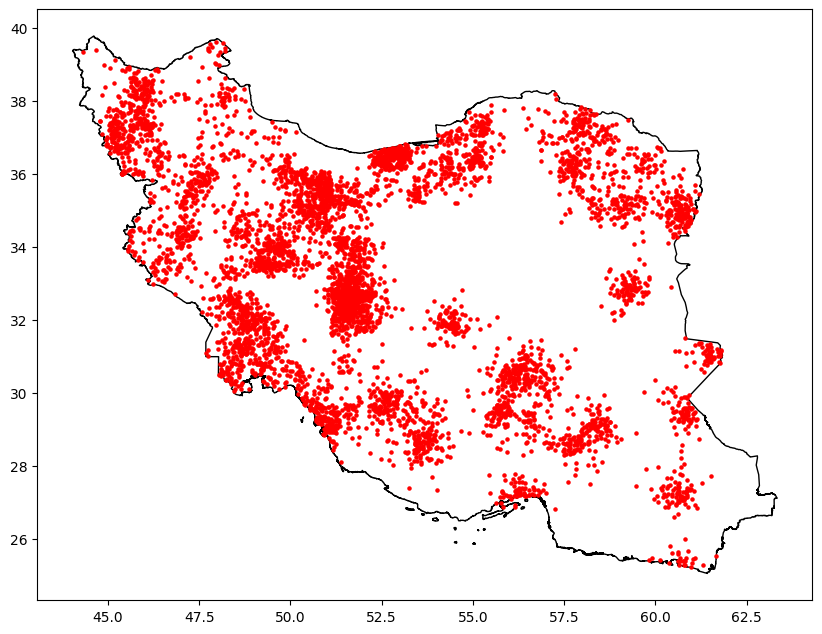

In [14]:
# Load the shapefile
iran_shapefile = gpd.read_file('/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/data_downloading/Iran_shp/irn_admbnda_adm0_unhcr_20190514.shp')

# Load the CSV file containing the coordinates
coords_df = pd.read_csv('/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/data_downloading/centroids_csv/center_coords_ssl4eo_iran.csv')

# Convert the DataFrame to a GeoDataFrame
gdf_coords = gpd.GeoDataFrame(coords_df, geometry=gpd.points_from_xy(coords_df.longitude, coords_df.latitude))

# Plot the shapefile and overlay the points
fig, ax = plt.subplots(figsize=(10, 10))
iran_shapefile.plot(ax=ax, color='white', edgecolor='black')
gdf_coords.plot(ax=ax, color='red', markersize=5)

plt.show()

## filter out complete set - 4849

In [73]:
complete_set = []    # s1, s2, lc
complete_s2set = []  # s2, lc
for nd in ndirs:
    fp = os.path.join(fdir_iran_data, f'{nd:07d}')
    fsubs = os.listdir(fp)
    if len(fsubs) == 3:
        complete_set.append(nd)
    if len(fsubs) >= 2:
        for fs in fsubs:
            if 'lc' in fs:
                complete_s2set.append(nd)
                break
len(complete_set), len(complete_s2set)

(4849, 5471)

In [83]:
df = save_meta_info(fdir_iran, complete_set, keys=['s1', 's2'])
df.shape

(4849, 6)

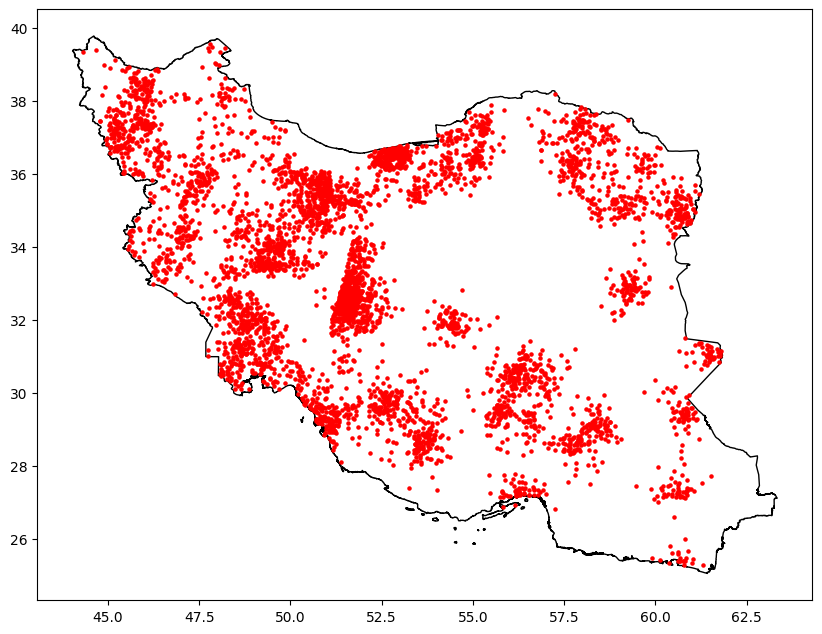

In [12]:
# Load the shapefile
iran_shapefile = gpd.read_file('/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/data_downloading/Iran_shp/irn_admbnda_adm0_unhcr_20190514.shp')

# Convert the DataFrame to a GeoDataFrame
gdf_points = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.lon, df.lat))

# Plot the shapefile and overlay the points
fig, ax = plt.subplots(figsize=(10, 10))
iran_shapefile.plot(ax=ax, color='white', edgecolor='black')
gdf_points.plot(ax=ax, color='red', markersize=5)

plt.show()

## add points (no data in this region)

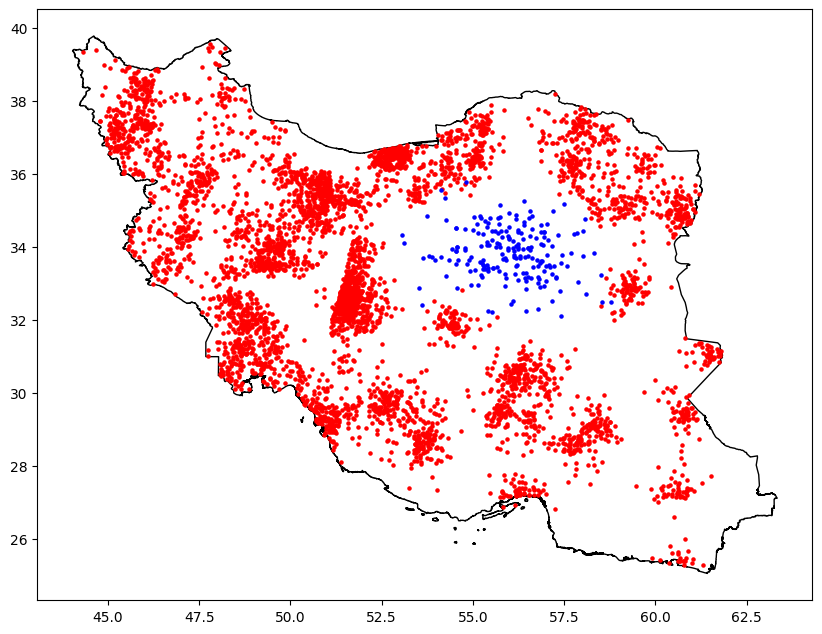

In [68]:
num_samples = 200
lon = np.random.normal(loc=56, scale=1, size=num_samples)
lat = np.random.normal(loc=33.9, scale=0.7, size=num_samples)

# Plot the shapefile and overlay the points
fig, ax = plt.subplots(figsize=(10, 10))
iran_shapefile.plot(ax=ax, color='white', edgecolor='black')
gdf_points.plot(ax=ax, color='red', markersize=5)

# additional points
# Convert the list of coordinates to a GeoDataFrame
gdf_coords_sampled = gpd.GeoDataFrame(geometry=gpd.points_from_xy([c for c in lon], [c for c in lat]))

# Plot the shapefile and overlay the sampled points
# fig, ax = plt.subplots(figsize=(10, 10))
# iran_shapefile.plot(ax=ax, color='white', edgecolor='black')
gdf_coords_sampled.plot(ax=ax, color='blue', markersize=5)

plt.show()

In [69]:
def drop_overlapping_points(gdf, tolerance=1e-9):
    # Reset index for clarity
    gdf = gdf.reset_index(drop=True)
    
    # Compute a mask where points are within a small tolerance of each other
    # (for exactly overlapping points, tolerance can be set to 0)
    duplicates = gdf.geometry.apply(lambda geom: gdf.distance(geom) < tolerance)

    to_drop = set()  # to store indices to drop

    # Iterate over each row to find overlaps
    for i, row in gdf.iterrows():
        if i in to_drop:
            continue  # skip if already marked to drop
        
        # Check which points are overlapping with this point (within tolerance)
        overlapping = duplicates.loc[i].loc[duplicates.loc[i]].index
        
        if len(overlapping) > 1:  # More than one overlapping point
            # Randomly choose one to keep, drop the others
            to_keep = np.random.choice(overlapping, 1)
            to_drop.update(overlapping.difference(to_keep))

    # Drop the points identified in to_drop
    return gdf.drop(list(to_drop))

# Example usage with a GeoDataFrame gdf:
# gdf = gpd.read_file("your_geodatafile.shp")  # Example for loading a geodataframe
cleaned_gdf = drop_overlapping_points(gdf_coords_sampled)
len(cleaned_gdf)


200

In [ ]:
# Add img_id column starting from 251176
cleaned_gdf['img_id'] = range(251176, 251176 + len(cleaned_gdf))

# Extract the required columns
cleaned_gdf_to_save = cleaned_gdf[['img_id', 'geometry']]

# Split the geometry column into lon and lat
cleaned_gdf_to_save['lon'] = cleaned_gdf_to_save.geometry.x
cleaned_gdf_to_save['lat'] = cleaned_gdf_to_save.geometry.y

# Save to CSV without header
cleaned_gdf_to_save[['img_id', 'lon', 'lat']].to_csv('cleaned_gdf.csv', index=False, header=False)

## show images

In [8]:
lc_dirs = []
lcs = []
for d in ndirs:
    fdir = os.path.join(fdir_iran, f'{d:07d}')
    subns = os.listdir(fdir)
    for sn in subns:
        if '.tif' in sn or '.tiff' in sn:
            lc_dirs.append(d)
            with rasterio.open(os.path.join(fdir, sn)) as src:
                lcs.append(src.read())
                break
len(lcs), len(lc_dirs)

(5404, 5404)

In [20]:
lcs_arr = np.concatenate(lcs, axis=0)
lcs_arr.shape, np.unique(lcs_arr)

((5404, 264, 264),
 array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13], dtype=uint8))

In [16]:
n_lc = []
for i in range(1, 14):
    n = np.sum(lcs_arr == i)
    n_lc.append(n)
    print(f'{i}: {n}, {(n/lcs_arr.size)*100:.2f}%')

1: 17250461, 4.58%
2: 2211363, 0.59%
3: 24886962, 6.61%
4: 60236746, 15.99%
5: 6003365, 1.59%
6: 2430473, 0.65%
7: 30753129, 8.17%
8: 6855430, 1.82%
9: 41618671, 11.05%
10: 12515579, 3.32%
11: 12033094, 3.19%
12: 115366008, 30.63%
13: 44475903, 11.81%


{'driver': 'GTiff', 'dtype': 'uint16', 'nodata': None, 'width': 264, 'height': 264, 'count': 13, 'crs': CRS.from_epsg(4326), 'transform': Affine(8.949169805154632e-05, 0.0, 60.32013025760275,
       0.0, -8.963185649715008e-05, 35.527307607127725), 'blockysize': 1, 'tiled': False, 'interleave': 'pixel'}
(13, 264, 264) uint16


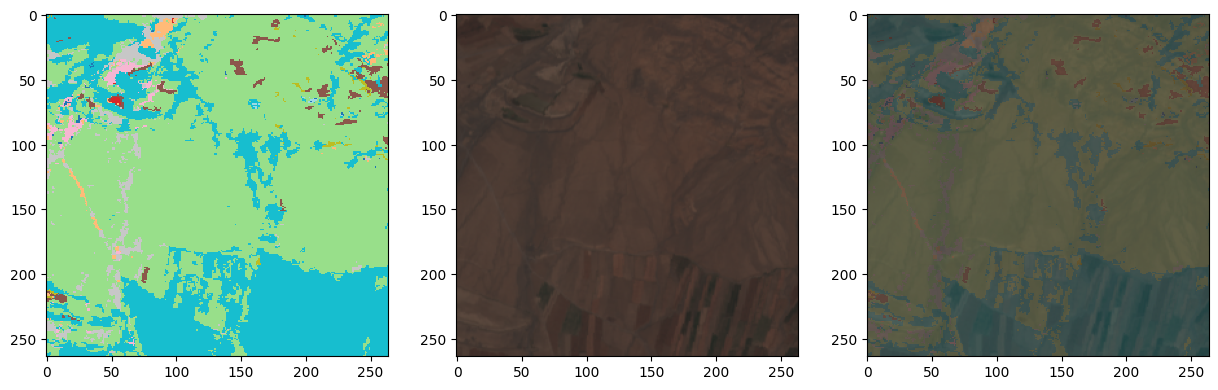

In [140]:
i = 10
fpp = os.path.join(fdir_iran, f'{lc_dirs[i]:07d}', 's2')
fp_s2 = os.path.join(fpp, os.listdir(fpp)[0])
with rasterio.open(fp_s2) as src:
    img = src.read()
    print(src.profile)
    print(img.shape, img.dtype)
plt.figure(figsize=(15, 5))
plt.subplot(131)
plt.imshow(lcs_arr[i], cmap='tab20', interpolation='none')
plt.subplot(132)
im = img[[3,2,1]].transpose(1,2,0)
im = im/10000 # (im - np.min(im)) / (np.max(im) - np.min(im))
plt.imshow(im)
plt.subplot(133)
plt.imshow(im)
plt.imshow(lcs_arr[i], cmap='tab20', alpha=0.2, interpolation='none')

## create lmdb

In [42]:
fp_lmdb = '/p/scratch/hai_ws4eo/liu_ch/data/WeakFT/Iran_w_weak_labels.lmdb'
lmdb_size = 10*1024**3

t0 = datetime.datetime.now().replace(microsecond=0)
env = lmdb.open(fp_lmdb, map_size=lmdb_size)
txn = env.begin(write=True)
for di, d in tqdm(enumerate(lc_dirs), total=len(lc_dirs)):
    fpp = os.path.join(fdir_iran, f'{d:07d}', 's2')
    fp_s2 = os.path.join(fpp, os.listdir(fpp)[0])
    with rasterio.open(fp_s2) as src:
        img = src.read()
    # data
    lbl = lcs_arr[di]
    obj = (img.tobytes(), img.shape, lbl.tobytes(), lbl.shape, f'{d:07d}'.encode())       
    txn.put(str(di).encode(), pickle.dumps(obj))            
txn.commit()
env.sync()
env.close()
t1 = datetime.datetime.now().replace(microsecond=0)
print(f'Elapsed time: {t1-t0}')

100%|██████████| 5404/5404 [00:57<00:00, 94.24it/s] 


Elapsed time: 0:01:01


In [141]:
S2C_MEAN = [1605.57504906, 1390.78157673, 1314.8729939, 1363.52445545, 1549.44374991, 2091.74883118, 2371.7172463, 2299.90463006, 2560.29504086, 830.06605044, 22.10351321, 2177.07172323, 1524.06546312]
S2C_STD = [786.78685367, 850.34818441, 875.06484736, 1138.84957046, 1122.17775652, 1161.59187054, 1274.39184232, 1248.42891965, 1345.52684884, 577.31607053, 51.15431158, 1336.09932639, 1136.53823676]

0000201 (13, 264, 264) (264, 264)


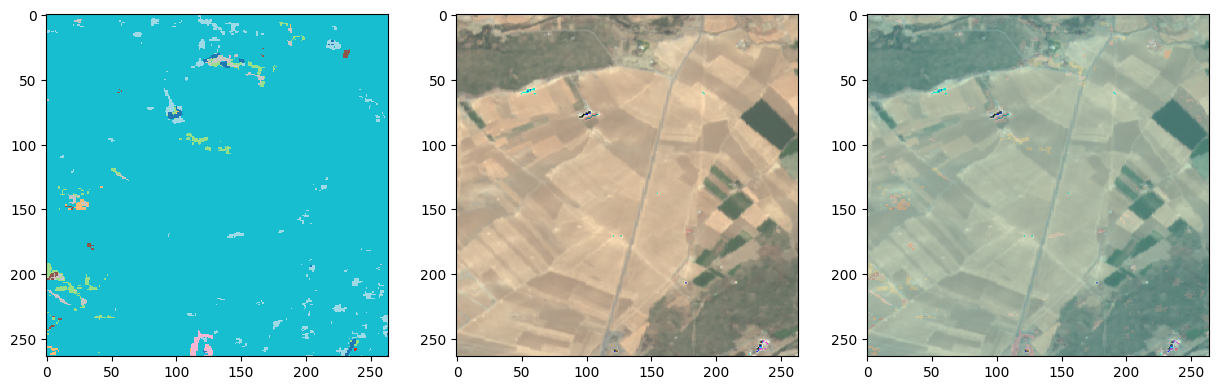

In [174]:
# check saved lmdb file
i = 2
env = lmdb.open(fp_lmdb, max_readers=1, readonly=True, lock=False, readahead=False, meminit=False)
with env.begin(write=False) as txn:
    obj = pickle.loads(txn.get(str(i).encode()))
    img = np.frombuffer(obj[0], dtype=np.uint16).reshape(obj[1])
    lbl = np.frombuffer(obj[2], dtype=np.uint8).reshape(obj[3])
    print(obj[4].decode(), img.shape, lbl.shape)
    plt.figure(figsize=(15, 5))
    plt.subplot(131)
    plt.imshow(lbl, cmap='tab20', interpolation='none')
    plt.subplot(132)
    # im = img[[3,2,1]].transpose(1,2,0)
    # im = (im - np.min(im)) / (np.max(im) - np.min(im))

    # # ssl4eo-s12_0k_251k_s2c_norm.lmdb (used by NS_Pr project)
    # im = []
    # for i in [3,2,1]:
    #     im_ = img[i].astype(np.float32)
    #     vmin = S2C_MEAN[i] - 2*S2C_STD[i]
    #     vmax = S2C_MEAN[i] + 2*S2C_STD[i]
    #     im_ = ((im_-vmin) / (vmax-vmin))*255
    #     im_ = im_.astype(np.uint8)
    #     im.append(im_)
    # im = np.stack(im, axis=2)
    
    # # ssl4eo-s12_0k_251k.lmdb
    # im = img[[3,2,1]].transpose(1,2,0)
    # im = im/10000 # (im - np.min(im)) / (np.max(im) - np.min(im))

    plt.imshow(im)
    plt.subplot(133)
    plt.imshow(im)
    plt.imshow(lbl, cmap='tab20', alpha=0.2, interpolation='none')

(251079, (4, 13, 264, 264))

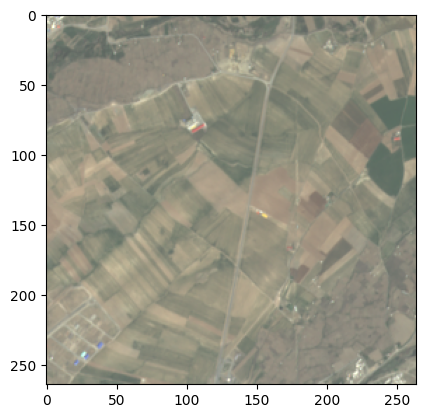

In [175]:
# get number of items in lmdb
fp = '/p/project1/hai_ssl4eo/wang_yi/data/ssl4eo-s12_0k_251k_s2c_norm.lmdb'
env = lmdb.open(fp, max_readers=1, readonly=True, lock=False, readahead=False, meminit=False)
with env.begin(write=False) as txn:
    n_items = txn.stat()['entries']
    key = str(201).encode()
    value = txn.get(key)
    obj = pickle.loads(value)
    img = np.frombuffer(obj[0], dtype=np.uint8).reshape(obj[1])
env.close()
plt.figure()
im = img[2].transpose(1,2,0)[:,:,[3,2,1]]
plt.imshow(im)
n_items, img.shape

(103794, (4, 13, 264, 264), 201)

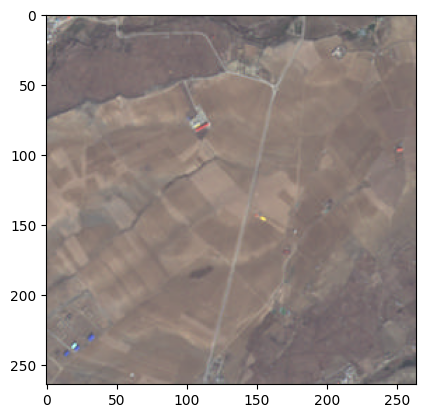

In [170]:
# get number of items in lmdb
fp = '/p/project1/hai_dm4eo/liu_ch/data/SSL4EO-S2/0k_251k_uint8_s2c.lmdb'
env = lmdb.open(fp, max_readers=1, readonly=True, lock=False, readahead=False, meminit=False)
with env.begin(write=False) as txn:
    n_items = txn.stat()['entries']
    key = str(91).encode()
    value = txn.get(key)
    obj = pickle.loads(value)
    img = np.frombuffer(obj[0], dtype=np.uint8).reshape(obj[1])
env.close()
plt.figure()
im = img[1].transpose(1,2,0)[:,:,[3,2,1]]
plt.imshow(im)
n_items, img.shape, obj[-1]

# WorldCover

## show SSL4EO-S12 spot distribution

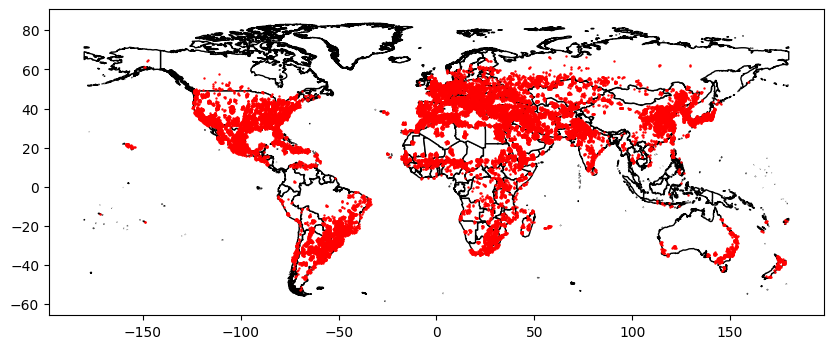

In [94]:
# Load the shapefile
world_shapefile = gpd.read_file('/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/data_downloading/world_shp/world-administrative-boundaries.shp')

# Load the CSV file containing the coordinates
coords_df = pd.read_csv('/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/data_downloading/centroids_csv/center_coords_subset_worldcover_from_ssl4eo.csv',
                        header=0, names=['id', 'longitude', 'latitude'])

# Convert the DataFrame to a GeoDataFrame
gdf_coords = gpd.GeoDataFrame(coords_df, geometry=gpd.points_from_xy(coords_df.longitude, coords_df.latitude))

# Plot the shapefile and overlay the points
fig, ax = plt.subplots(figsize=(10, 10))
world_shapefile.plot(ax=ax, color='white', edgecolor='black')
gdf_coords.plot(ax=ax, color='red', markersize=.5)

plt.show()

## filter out complete set

In [84]:
dfs = {}
for v in [100, 200]:
    dataset = f'worldcover_v{v}'
    fdir = f'/p/scratch/hai_ws4eo/liu_ch/data/WeakFT/{dataset}'
    complete_set, org_n = get_complete_set(fdir, n=4)
    df = save_meta_info(fdir, complete_set, keys=['s1', 's2', 's2a'])
    dfs[dataset] = df
    print(f'{dataset}: {df.shape}')


worldcover_v100: (40700, 7)
worldcover_v200: (40412, 7)


## overlap - 38873

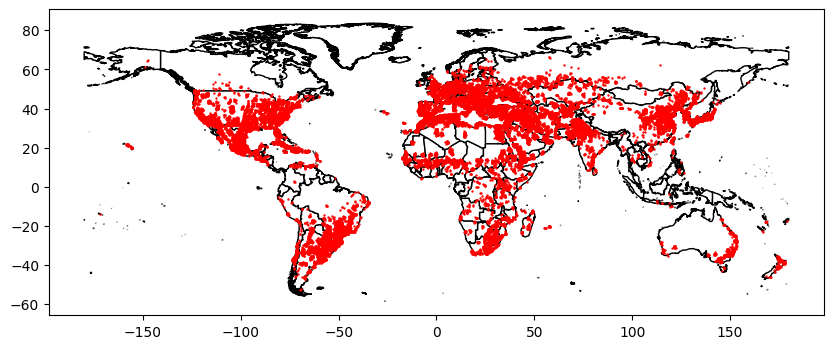

38873

In [143]:
d1 = dfs['worldcover_v100'].id
d2 = dfs['worldcover_v200'].id
overlap = d1[d1.isin(d2)]
overlap_points = dfs['worldcover_v100'].iloc[overlap.index, [0, 5, 6]]
overlap_points.to_csv('/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/data_downloading/centroids_used/center_coords_overlap_worldcover.csv', index=False)
gdf_overlap_points = gpd.GeoDataFrame(overlap_points, geometry=gpd.points_from_xy(overlap_points.lon, overlap_points.lat))
fig, ax = plt.subplots(figsize=(10, 10))
world_shapefile.plot(ax=ax, color='white', edgecolor='black')
gdf_overlap_points.plot(ax=ax, color='red', markersize=.5)
plt.show()
len(overlap_points)

# NLCD

## get sampling points from SSL4EO-L benchmark

In [89]:
pdir = '/p/scratch/hai_ws4eo/liu_ch/data/WeakFT/ssl4eo_l_oli_nlcd'
ids = [int(i) for i in os.listdir(pdir)]
ids.sort()
landsat_names, crs, bounds, lons, lats = [], [], [], [], []
for i in tqdm(ids, total=len(ids)):
    fsubd = os.path.join(pdir, f'{i:07d}')
    fsub = os.listdir(fsubd)[0]
    landsat_names.append(fsub)
    fp = os.path.join(fsubd, fsub, 'nlcd_2019.tif')

    # open data to get meta info
    with rasterio.open(fp) as src:
        crs_ = src.crs
        bound = src.bounds
        width = src.width
        height = src.height
        
        # Get the affine transform of the raster (maps pixel space to geographic coordinates)
        transform = src.transform
        
    # Calculate the coordinates of the center pixel (width // 2, height // 2)
    center_pixel_x = width // 2
    center_pixel_y = height // 2
    
    # Get the center point coordinates using the affine transform
    center_lon, center_lat = transform * (center_pixel_x, center_pixel_y)
    lons.append(center_lon)
    lats.append(center_lat)
    crs.append(crs_)
    bounds.append(bound)

df = pd.DataFrame({'id': ids, 'landsat_name': landsat_names, 'crs': crs, 
                   'bounds': bounds, 'longitude': lons, 'latitude': lats})
df.to_csv('/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/data_downloading/centroids_used/center_coords_usa.csv', index=False)
df.shape

100%|██████████| 25000/25000 [07:49<00:00, 53.20it/s]


(25000, 6)

In [4]:
df = pd.read_csv('/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/data_downloading/centroids_used/center_coords_usa.csv', header=0)
df_err = pd.read_csv('/p/scratch/hai_dm4eo/liu_ch/data/WeakFT/nlcd/Error_message.csv', header=0)
merged_df = pd.merge(df, df_err, left_on='id', right_on='img_id')
merged_df.shape, merged_df.head

((6241, 8),
 <bound method NDFrame.head of          id          landsat_name        crs  \
 0         4  LC08_015032_20190812  EPSG:4326   
 1        15  LC08_034032_20190716  EPSG:4326   
 2        16  LC08_019032_20190824  EPSG:4326   
 3        21  LC08_040036_20190827  EPSG:4326   
 4        23  LC08_016035_20190819  EPSG:4326   
 ...     ...                   ...        ...   
 6236  29427  LC08_040036_20190827  EPSG:4326   
 6237  29428  LC08_042029_20190724  EPSG:4326   
 6238  29432  LC08_028028_20190706  EPSG:4326   
 6239  29434  LC08_031029_20190828  EPSG:4326   
 6240  29439  LC08_029032_20190729  EPSG:4326   
 
                                                  bounds   longitude  \
 0     BoundingBox(left=-76.12441300415868, bottom=39...  -76.078782   
 1     BoundingBox(left=-105.38072285670093, bottom=4... -105.334225   
 2     BoundingBox(left=-82.76593253823124, bottom=40...  -82.720700   
 3     BoundingBox(left=-116.27786952542276, bottom=3... -116.235095   
 4     B

In [6]:
merged_df.to_csv('/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/data_downloading/centroids_used/center_coords_usa_err.csv', index=False)

In [156]:
import re

def read_coords(bbox_str):
    # Regular expression to extract the values of left, bottom, right, and top
    pattern = r'left=(-?\d+\.\d+), bottom=(-?\d+\.\d+), right=(-?\d+\.\d+), top=(-?\d+\.\d+)'

    # Find all matches
    matches = re.search(pattern, bbox_str)

    # If matches are found, extract them into variables
    left = float(matches.group(1))
    bottom = float(matches.group(2))
    right = float(matches.group(3))
    top = float(matches.group(4))

    coords = [[left, top], [right, bottom]]
    return coords

a = 'BoundingBox(left=-121.26689204879368, bottom=43.03824232719704, right=-121.17212056414569, top=43.10791616277853)'
read_coords(a)

[[-121.26689204879368, 43.10791616277853],
 [-121.17212056414569, 43.03824232719704]]

(29, 1)


<Axes: >

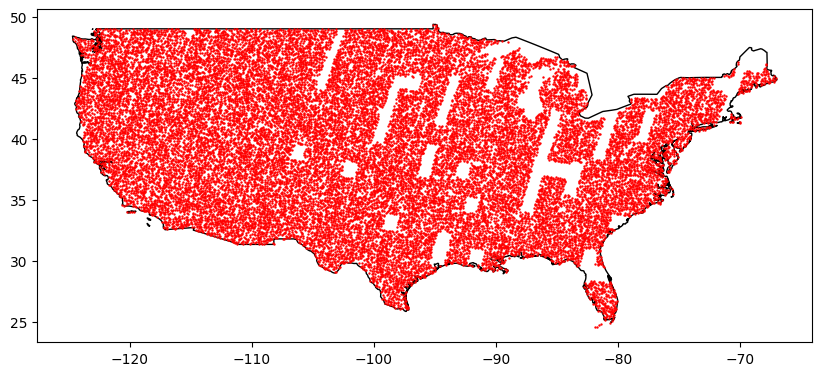

In [125]:
# create continental US shapefile
world_shapefile = gpd.read_file('/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/data_downloading/world_shp/world-administrative-boundaries.shp')
# Create an empty list to store individual polygons
us_shapefile = world_shapefile[world_shapefile['name'] == 'United States of America']
split_polygons = []
min_longitude, max_longitude = -128, -50

# Iterate over each geometry in the GeoDataFrame
for geom in us_shapefile.geometry:
    if isinstance(geom, MultiPolygon):
        # If the geometry is a MultiPolygon, iterate over individual polygons
        for poly in geom.geoms:
            # Check the bounds of the polygon (min_x, min_y, max_x, max_y)
            if poly.bounds[0] >= min_longitude and poly.bounds[2] <= max_longitude:
                split_polygons.append(poly)
    else:
        # If the geometry is already a Polygon, check its bounds
        if geom.bounds[0] >= min_longitude and geom.bounds[2] <= max_longitude:
            split_polygons.append(geom)

# Create a new GeoDataFrame with the split polygons
split_gdf = gpd.GeoDataFrame(geometry=split_polygons)
print(split_gdf.shape)

# plot the points
gdf_nlcd = gpd.GeoDataFrame(geometry=gpd.points_from_xy(df.lon, df.lat))
fig, ax = plt.subplots(figsize=(10, 10))
split_gdf.plot(ax=ax, color='white', edgecolor='black')
gdf_nlcd.plot(ax=ax, color='red', markersize=.5)

# plot ssl4eo-s12 points

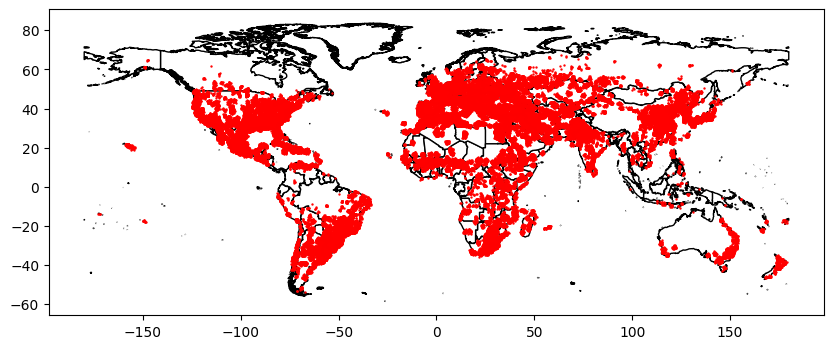

In [140]:
# Load the shapefile
world_shapefile = gpd.read_file('/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/data_downloading/world_shp/world-administrative-boundaries.shp')

# Load the CSV file containing the coordinates
coords_df = pd.read_csv('/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/data_downloading/centroids_csv/center_coords_ssl4eo_save_order.csv',
                        names=['id', 'longitude', 'latitude'])

# Convert the DataFrame to a GeoDataFrame
gdf_coords = gpd.GeoDataFrame(coords_df, geometry=gpd.points_from_xy(coords_df.longitude, coords_df.latitude))

# Plot the shapefile and overlay the points
fig, ax = plt.subplots(figsize=(10, 10))
world_shapefile.plot(ax=ax, color='white', edgecolor='black')
gdf_coords.plot(ax=ax, color='red', markersize=.5)

plt.show()

In [8]:
# count number of points every 10 degrees along latitude
lats = np.arange(-90, 90, 10)
n_ps = []
for lat in lats:
    n_ps.append(len(gdf_coords[(gdf_coords.latitude >= lat) & (gdf_coords.latitude < lat+20)])) 
n_ps

[0,
 0,
 29,
 844,
 13535,
 33096,
 25013,
 6747,
 4629,
 21367,
 50765,
 127361,
 141531,
 61282,
 15577,
 382,
 0,
 0]

## usa split

In [3]:
# create continental US shapefile
# Create an empty list to store individual polygons
us_shapefile = world_shapefile[world_shapefile['name'] == 'United States of America']
split_polygons = []
min_longitude, max_longitude = -128, -50

# Iterate over each geometry in the GeoDataFrame
for geom in us_shapefile.geometry:
    if isinstance(geom, MultiPolygon):
        # If the geometry is a MultiPolygon, iterate over individual polygons
        for poly in geom.geoms:
            # Check the bounds of the polygon (min_x, min_y, max_x, max_y)
            if poly.bounds[0] >= min_longitude and poly.bounds[2] <= max_longitude:
                split_polygons.append(poly)
    else:
        # If the geometry is already a Polygon, check its bounds
        if geom.bounds[0] >= min_longitude and geom.bounds[2] <= max_longitude:
            split_polygons.append(geom)

# Create a new GeoDataFrame with the split polygons
split_gdf = gpd.GeoDataFrame(geometry=split_polygons)
print(split_gdf.shape)
# # Save the split polygons to a new shapefile (optional)
# split_gdf.to_file('/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/data_downloading/world_shp/continental_usa.shp')

(29, 1)


/p/project/hai_dm4eo/jupyter_kernel_venvs/liu18_kernel24/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3517: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  if await self.run_code(code, result, async_=asy):


(73265, 3)


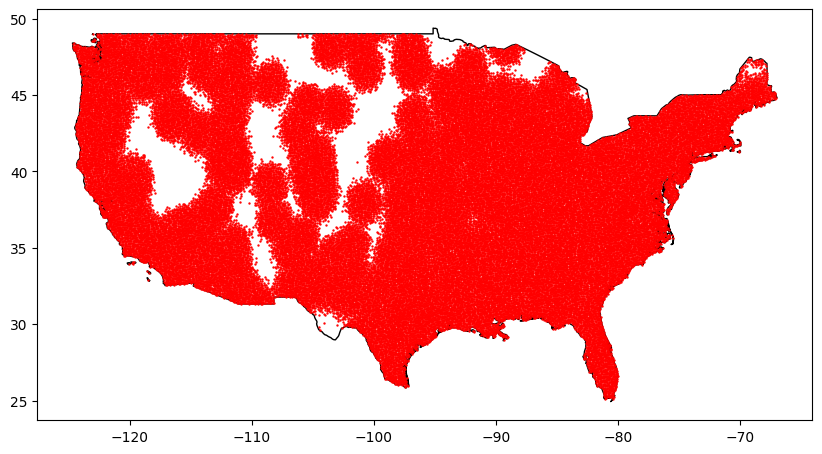

In [4]:
fig, ax = plt.subplots(figsize=(10, 10))
split_gdf.plot(ax=ax, color='white', edgecolor='black')

# Spatial join to filter points within the polygon(s)
gdf_coords.set_crs('EPSG:4326', inplace=True)
points_in_US = gpd.sjoin(gdf_coords, us_shapefile, op='within')
points_in_US = points_in_US[(points_in_US.longitude >= min_longitude) & (points_in_US.longitude < max_longitude)]
points_in_US.plot(ax=ax, color='red', markersize=.5)
points_to_save = points_in_US[['id', 'longitude', 'latitude']]
print(points_to_save.shape)
# points_to_save.to_csv('/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/data_downloading/centroids_csv/center_coords_subset_usa_from_ssl4eo.csv',
#                     index=False)

<Axes: >

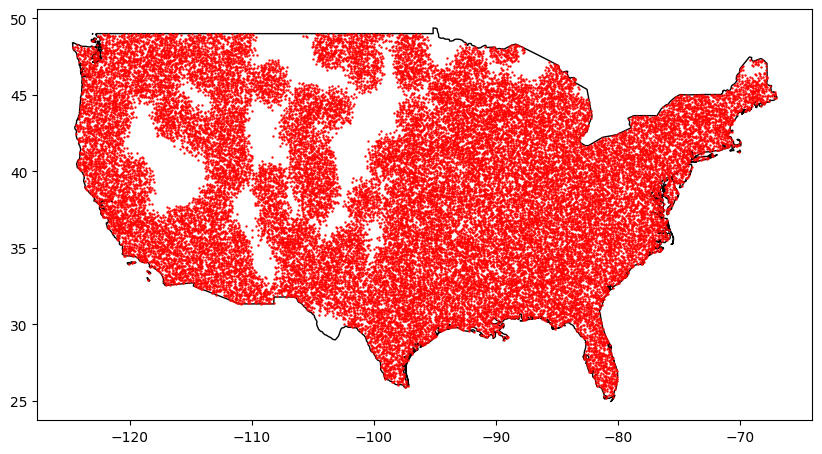

In [8]:
n = 35000
fig, ax = plt.subplots(figsize=(10, 10))
split_gdf.plot(ax=ax, color='white', edgecolor='black')

inds = np.arange(0, len(points_to_save))
np.random.shuffle(inds)

points = points_in_US.iloc[inds[:n]]
points.plot(ax=ax, color='red', markersize=.5)

# # Spatial join to filter points within the polygon(s)
# gdf_coords.set_crs('EPSG:4326', inplace=True)
# points_in_US = gpd.sjoin(gdf_coords, us_shapefile, op='within')
# points_in_US = points_in_US[(points_in_US.longitude >= min_longitude) & (points_in_US.longitude < max_longitude)]
# points_in_US.plot(ax=ax, color='red', markersize=.5)
# points_to_save = points_in_US[['id', 'longitude', 'latitude']]
# print(points_to_save.shape)

/p/project/hai_dm4eo/jupyter_kernel_venvs/liu18_kernel24/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3517: FutureWarning: The `op` parameter is deprecated and will be removed in a future release. Please use the `predicate` parameter instead.
  if await self.run_code(code, result, async_=asy):


(39470, 3)


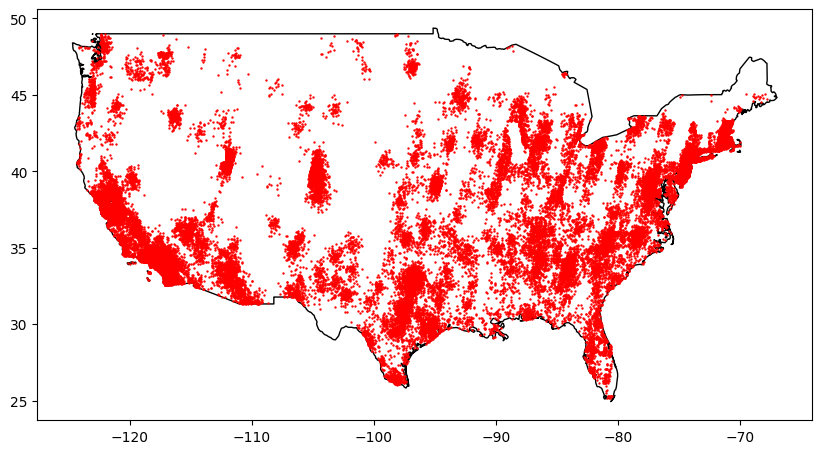

In [5]:
# Load the CSV file containing the coordinates
coords_df = pd.read_csv('/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/data_downloading/centroids_csv/center_coords_ssl4eo_save_order.csv',
                        names=['id', 'longitude', 'latitude'])
# Convert the DataFrame to a GeoDataFrame
gdf_coords_s = gpd.GeoDataFrame(coords_df, geometry=gpd.points_from_xy(coords_df.longitude, coords_df.latitude))

fig, ax = plt.subplots(figsize=(10, 10))
split_gdf.plot(ax=ax, color='white', edgecolor='black')

# Spatial join to filter points within the polygon(s)
gdf_coords_s.set_crs('EPSG:4326', inplace=True)
points_in_US_s = gpd.sjoin(gdf_coords_s, us_shapefile, op='within')
points_in_US_s = points_in_US_s[(points_in_US_s.longitude >= min_longitude) & (points_in_US_s.longitude < max_longitude)]
points_in_US_s.plot(ax=ax, color='red', markersize=.5)
points_to_save_s = points_in_US_s[['id', 'longitude', 'latitude']]
print(points_to_save_s.shape)

In [45]:
len(points_in_US)

39470

In [10]:
points_in_US.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [12]:
points_in_US

,id,longitude,latitude,geometry,index_right,iso3,status,color_code,name,continent,region,iso_3166_1_,french_shor,buffer
8,8,-110.972010,31.733941,POINT (-110.97201 31.73394),49,USA,Member State,USA,United States of America,Americas,Northern America,US,États-Unis d'Amérique,"POLYGON ((-80.97201 31.73394, -81.11647 28.793..."
13,13,-74.209288,39.861987,POINT (-74.20929 39.86199),49,USA,Member State,USA,United States of America,Americas,Northern America,US,États-Unis d'Amérique,"POLYGON ((-44.20929 39.86199, -44.35375 36.921..."
27,27,-111.824236,40.467716,POINT (-111.82424 40.46772),49,USA,Member State,USA,United States of America,Americas,Northern America,US,États-Unis d'Amérique,"POLYGON ((-81.82424 40.46772, -81.96869 37.527..."
29,29,-83.956848,42.275871,POINT (-83.95685 42.27587),49,USA,Member State,USA,United States of America,Americas,Northern America,US,États-Unis d'Amérique,"POLYGON ((-53.95685 42.27587, -54.10131 39.335..."
33,33,-118.536273,34.078144,POINT (-118.53627 34.07814),49,USA,Member State,USA,United States of America,Americas,Northern America,US,États-Unis d'Amérique,"POLYGON ((-88.53627 34.07814, -88.68073 31.137..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
251044,251141,-87.018985,41.187498,POINT (-87.01899 41.18750),49,USA,Member State,USA,United States of America,Americas,Northern America,US,États-Unis d'Amérique,"POLYGON ((-57.01899 41.18750, -57.16344 38.246..."
251059,251156,-97.318240,28.043448,POINT (-97.31824 28.04345),49,USA,Member State,USA,United States of America,Americas,Northern America,US,États-Unis d'Amérique,"POLYGON ((-67.31824 28.04345, -67.46270 25.102..."
251070,251167,-84.336018,33.750577,POINT (-84.33602 33.75058),49,USA,Member State,USA,United States of America,Americas,Northern America,US,États-Unis d'Amérique,"POLYGON ((-54.33602 33.75058, -54.48048 30.810..."
251077,251174,-80.834308,26.387706,POINT (-80.83431 26.38771),49,USA,Member State,USA,United States of America,Americas,Northern America,US,États-Unis d'Amérique,"POLYGON ((-50.83431 26.38771, -50.97877 23.447..."


## create splits

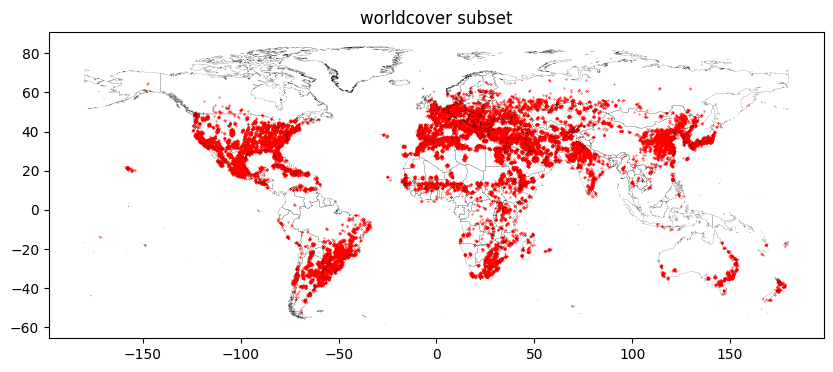

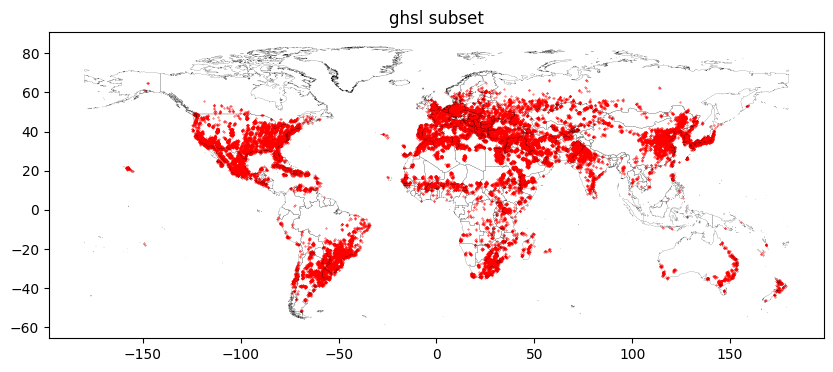

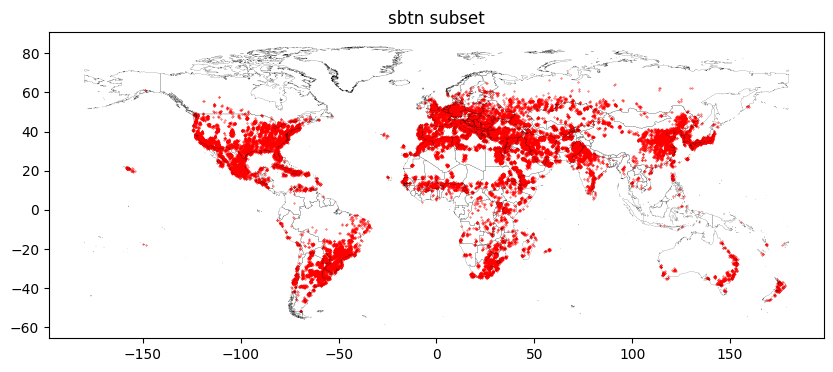

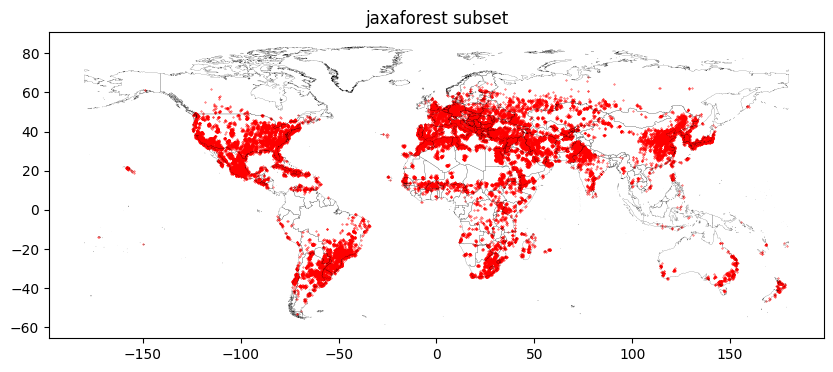

In [51]:
# split center coordinates into 5 subsets with each of a size of 50k
csv_dir = '/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/data_downloading/centroids_csv'
ssl4eo_csv = 'center_coords_ssl4eo_save_order.csv'
df = pd.read_csv(os.path.join(csv_dir, ssl4eo_csv), names=['id', 'longitude', 'latitude'])
inds = np.arange(len(df))
np.random.shuffle(inds)

# world shapefile
world_shapefile = gpd.read_file('/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/data_downloading/world_shp/world-administrative-boundaries.shp')
world_shapefile = world_shapefile.to_crs(epsg=4326) 

# split
subset_size = 50000
subset_names = ['worldcover', 'ghsl', 'sbtn', 'jaxaforest']
subdfs = []
for i, subset_name in enumerate(subset_names):
    subdf = df.iloc[inds[i*subset_size:(i+1)*subset_size]]
    fp_sub = os.path.join(csv_dir, f'center_coords_subset_{subset_name}_from_ssl4eo.csv')
    subdf.to_csv(fp_sub, index=False)
    # plot points
    fig, ax = plt.subplots(figsize=(10, 10))
    world_shapefile.boundary.plot(ax=ax, edgecolor='black', linewidth=.1)
    sdf = gpd.GeoDataFrame(subdf, geometry=gpd.points_from_xy(subdf.iloc[:,1], subdf.iloc[:,2]))
    sdf.plot(ax=ax, color='red', markersize=.1)
    plt.title(f'{subset_name} subset')

In [52]:
csv_path = '/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/data_downloading/centroids_csv/center_coords_subset_worldcover_from_ssl4eo.csv'
geo_data = pd.read_csv(csv_path, header=0)
geo_data

,id,longitude,latitude
0,201414,118.437879,37.227436
1,80719,120.962813,37.125954
2,68010,13.700810,45.415281
3,11473,-105.074348,39.762541
4,92122,18.709153,50.568060
...,...,...,...
49995,129436,-50.031096,-24.589547
49996,221207,-64.817490,-24.790292
49997,139337,33.671878,35.113503
49998,243109,23.983895,48.994643


# plot ssl4eo-l points

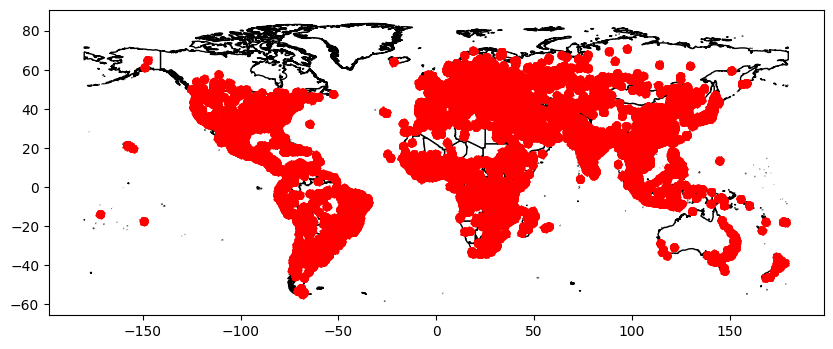

In [164]:
# Load the shapefile
world_shapefile = gpd.read_file('/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/data_downloading/world_shp/world-administrative-boundaries.shp')

# Load the CSV file containing the coordinates
coords_df = pd.read_csv('/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/data_downloading/centroids_csv/center_coords_ssl4eol.csv',
                        names=['id', 'longitude', 'latitude'])

# Convert the DataFrame to a GeoDataFrame
gdf_coords = gpd.GeoDataFrame(coords_df, geometry=gpd.points_from_xy(coords_df.longitude, coords_df.latitude))

# Plot the shapefile and overlay the points
fig, ax = plt.subplots(figsize=(10, 10))
world_shapefile.plot(ax=ax, color='white', edgecolor='black')
gdf_coords.plot(ax=ax, color='red', markersize=.5)

plt.show()

Text(0.5, 1.0, 'sbtn subset')

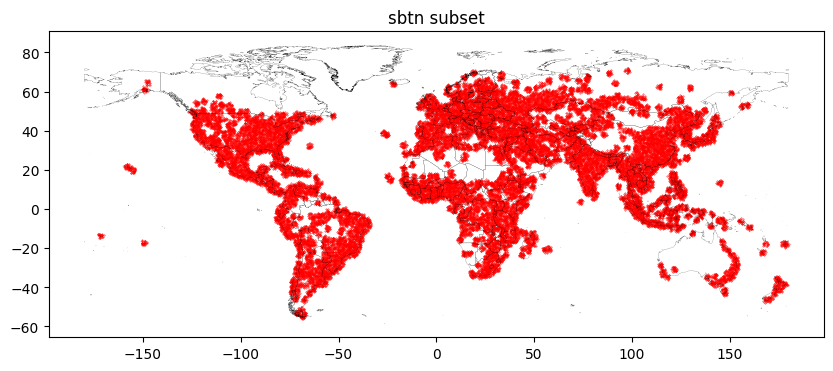

In [176]:
# split one subset of a size of 50k
subset_size = 50000
csv_dir = '/p/project1/hai_ws4eo/liu_ch/Weak_FT/segment-anything-2/data_downloading/centroids_csv'
inds = np.arange(len(coords_df))
np.random.shuffle(inds)

# split
subset_name = 'sbtn'
subdf = gdf_coords.iloc[inds[0:subset_size]]
fp_sub = os.path.join(csv_dir, f'center_coords_subset_{subset_name}_from_ssl4eo_l.csv')
subdf.iloc[:,:3].to_csv(fp_sub, index=False)
# plot points
fig, ax = plt.subplots(figsize=(10, 10))
world_shapefile.boundary.plot(ax=ax, edgecolor='black', linewidth=.1)
sdf = gpd.GeoDataFrame(geometry=gpd.points_from_xy(subdf.iloc[:,1], subdf.iloc[:,2]))
sdf.plot(ax=ax, color='red', markersize=.1)
plt.title(f'{subset_name} subset')

In [175]:
gdf_coords.shape, subdf.shape

((1000000, 4), (50000, 4))